<a href="https://colab.research.google.com/github/kananshr13/CSET-343-Ai-in-Healthcare/blob/main/Lab_Assignment_10_CSET343.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install wfdb numpy pandas matplotlib seaborn scikit-learn tensorflow

In [5]:
import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import butter, filtfilt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [6]:
import os

os.makedirs("mitdb", exist_ok=True)

wfdb.dl_database(
    "mitdb",
    dl_dir="mitdb"
)

print("MIT-BIH dataset downloaded successfully!")

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

In [7]:
record_name = "100"

record = wfdb.rdrecord(
    f"mitdb/{record_name}"
)

annotation = wfdb.rdann(
    f"mitdb/{record_name}",
    "atr"
)

signal = record.p_signal
sampling_rate = record.fs

print("Signal shape:", signal.shape)
print("Sampling rate:", sampling_rate)
print("Number of annotations:", len(annotation.sample))

Signal shape: (650000, 2)
Sampling rate: 360
Number of annotations: 2274


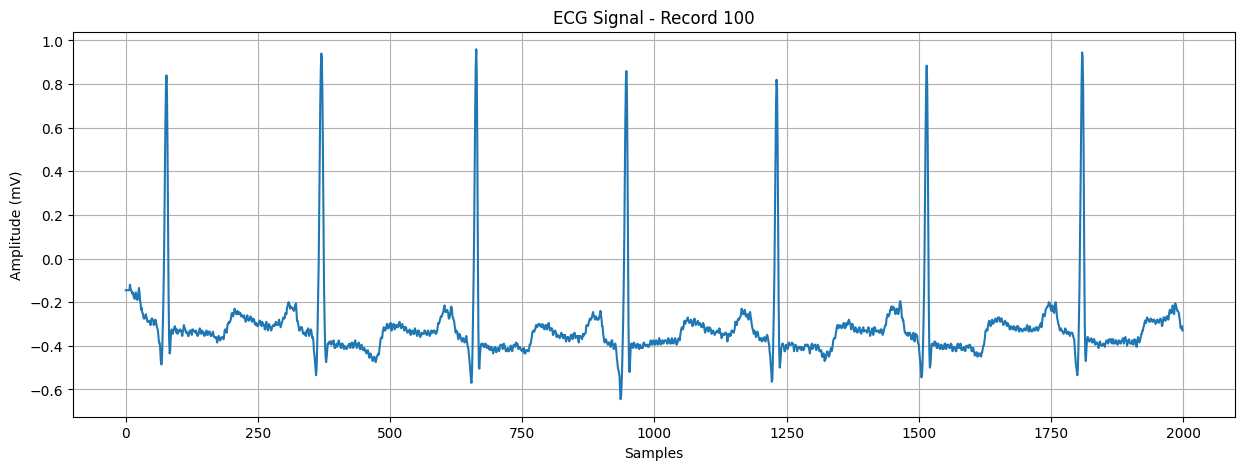

In [8]:
plt.figure(figsize=(15, 5))

plt.plot(signal[:2000, 0])

plt.title("ECG Signal - Record 100")
plt.xlabel("Samples")
plt.ylabel("Amplitude (mV)")

plt.grid()
plt.show()

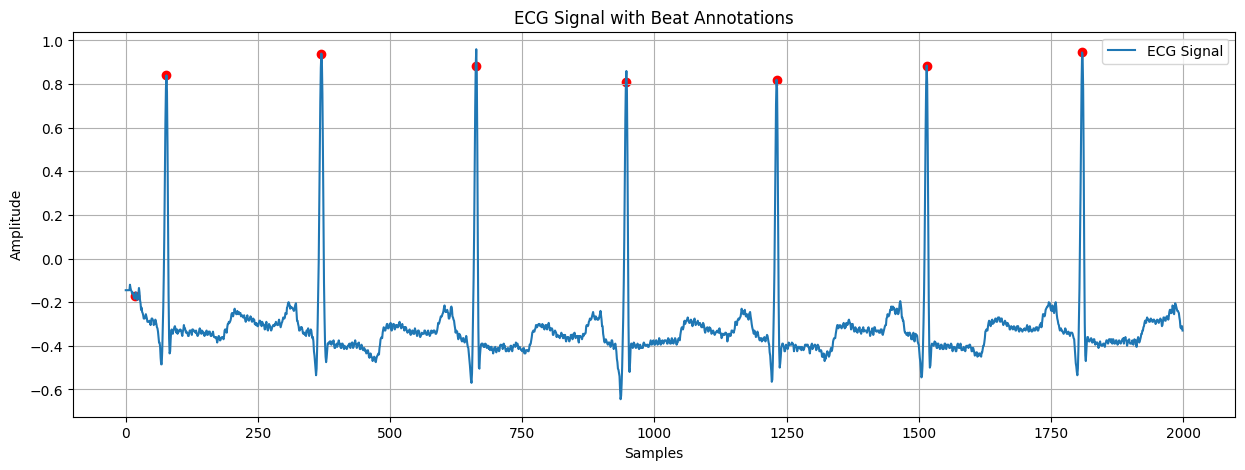

In [9]:
plt.figure(figsize=(15, 5))

plt.plot(signal[:2000, 0], label="ECG Signal")

for sample, symbol in zip(annotation.sample, annotation.symbol):
    if sample < 2000:
        plt.scatter(
            sample,
            signal[sample, 0],
            color="red"
        )

plt.title("ECG Signal with Beat Annotations")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.legend()
plt.grid()
plt.show()

In [10]:
AAMI_CLASSES = {
    "N": ["N", "L", "R", "e", "j"],
    "S": ["A", "a", "J", "S"],
    "V": ["V", "E"],
    "F": ["F"],
    "Q": ["/", "f", "Q"]
}

def map_beat(symbol):
    for class_name, symbols in AAMI_CLASSES.items():
        if symbol in symbols:
            return class_name
    return None

In [11]:
def bandpass_filter(signal, fs=360, low=0.5, high=40):
    nyquist = fs / 2

    low_cut = low / nyquist
    high_cut = high / nyquist

    b, a = butter(
        4,
        [low_cut, high_cut],
        btype="band"
    )

    filtered_signal = filtfilt(b, a, signal)

    return filtered_signal

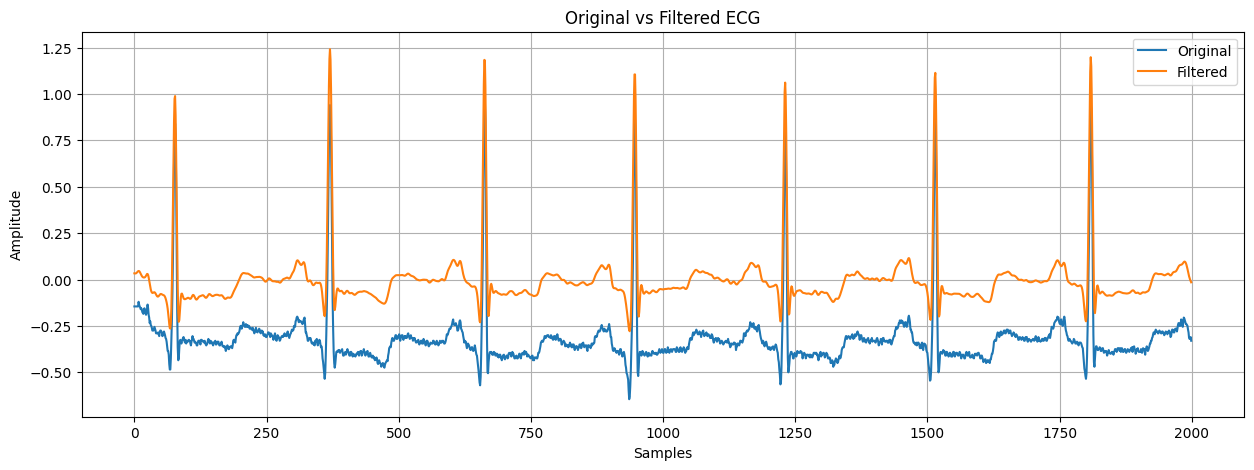

In [12]:
filtered_signal = bandpass_filter(
    signal[:, 0],
    sampling_rate
)

plt.figure(figsize=(15, 5))

plt.plot(signal[:2000, 0], label="Original")
plt.plot(filtered_signal[:2000], label="Filtered")

plt.title("Original vs Filtered ECG")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.legend()
plt.grid()
plt.show()

In [13]:
WINDOW_BEFORE = 90
WINDOW_AFTER = 110

X = []
y = []

records = wfdb.get_record_list("mitdb")

for record_name in records:

    try:

        record = wfdb.rdrecord(
            f"mitdb/{record_name}"
        )

        annotation = wfdb.rdann(
            f"mitdb/{record_name}",
            "atr"
        )

        ecg = record.p_signal[:, 0]

        ecg = bandpass_filter(
            ecg,
            record.fs
        )

        for sample, symbol in zip(
            annotation.sample,
            annotation.symbol
        ):

            label = map_beat(symbol)

            if label is None:
                continue

            start = sample - WINDOW_BEFORE
            end = sample + WINDOW_AFTER

            if start < 0 or end > len(ecg):
                continue

            beat = ecg[start:end]

            X.append(beat)
            y.append(label)

    except Exception as e:
        print("Skipping record:", record_name, e)

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (109465, 200)
y shape: (109465,)


N    90605
Q     8042
V     7235
S     2781
F      802
Name: count, dtype: int64


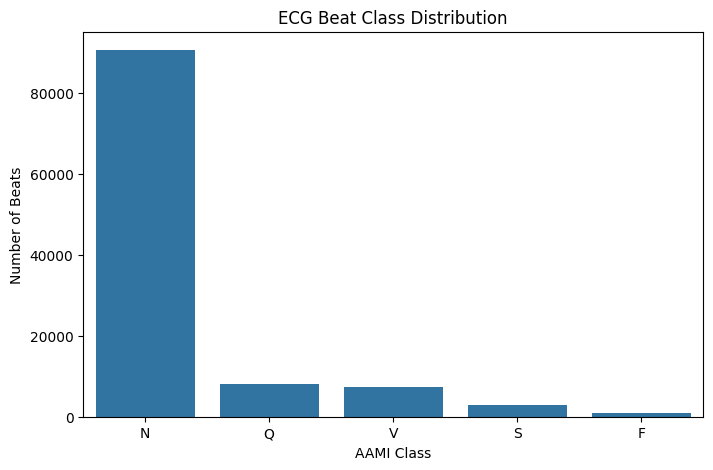

In [14]:

class_distribution = pd.Series(y).value_counts()

print(class_distribution)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_distribution.index,
    y=class_distribution.values
)

plt.title("ECG Beat Class Distribution")
plt.xlabel("AAMI Class")
plt.ylabel("Number of Beats")

plt.show()

In [15]:

X_normalized = []

for beat in X:

    mean = np.mean(beat)
    std = np.std(beat)

    normalized = (beat - mean) / (std + 1e-8)

    X_normalized.append(normalized)

X = np.array(X_normalized)

print("Normalized shape:", X.shape)

Normalized shape: (109465, 200)


In [16]:

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)

Classes: ['F' 'N' 'Q' 'S' 'V']


In [17]:

X = X.reshape(
    X.shape[0],
    X.shape[1],
    1
)

print("Final X shape:", X.shape)

Final X shape: (109465, 200, 1)


In [18]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (87572, 200, 1)
Testing data: (21893, 200, 1)


In [19]:

def create_rnn_model():

    model = Sequential([
        SimpleRNN(
            64,
            input_shape=(X_train.shape[1], 1)
        ),

        Dropout(0.3),

        Dense(32, activation="relu"),

        Dense(
            len(label_encoder.classes_),
            activation="softmax"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [20]:

rnn_model = create_rnn_model()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

rnn_history = rnn_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 23s 18ms/step - accuracy: 0.8187 - loss: 0.6425 - val_accuracy: 0.8304 - val_loss: 0.5945
Epoch 2/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 16s 14ms/step - accuracy: 0.8242 - loss: 0.5941 - val_accuracy: 0.8390 - val_loss: 0.5771
Epoch 3/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - accuracy: 0.8250 - loss: 0.5959 - val_accuracy: 0.8175 - val_loss: 0.5667
Epoch 4/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - accuracy: 0.8248 - loss: 0.5838 - val_accuracy: 0.8304 - val_loss: 0.5553
Epoch 5/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - accuracy: 0.8273 - loss: 0.5994 - val_accuracy: 0.8333 - val_loss: 0.5719
Epoch 6/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - accuracy: 0.8309 - loss: 0.5907 - val_accuracy: 0.8466 - val_loss: 0.5600
Epoch 7/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - accuracy: 0.8358 - loss: 0.5770 - val_accuracy: 0.8573 - val_loss: 0.5383
Epoch 8/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - accuracy: 0.8338 -

In [21]:

def create_lstm_model():

    model = Sequential([
        LSTM(
            64,
            input_shape=(X_train.shape[1], 1)
        ),

        Dropout(0.3),

        Dense(32, activation="relu"),

        Dense(
            len(label_encoder.classes_),
            activation="softmax"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [22]:

lstm_model = create_lstm_model()

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.8493 - loss: 0.5183 - val_accuracy: 0.8844 - val_loss: 0.3586
Epoch 2/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.8625 - loss: 0.4969 - val_accuracy: 0.8293 - val_loss: 0.5828
Epoch 3/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.8286 - loss: 0.5662 - val_accuracy: 0.8304 - val_loss: 0.6373
Epoch 4/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.8437 - loss: 0.5571 - val_accuracy: 0.9101 - val_loss: 0.3302
Epoch 5/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.9130 - loss: 0.3217 - val_accuracy: 0.9256 - val_loss: 0.2848
Epoch 6/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.9236 - loss: 0.2871 - val_accuracy: 0.9324 - val_loss: 0.2459
Epoch 7/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.9275 - loss: 0.2743 - val_accuracy: 0.9490 - val_loss: 0.2187
Epoch 8/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.9399 -

In [23]:

def create_gru_model():

    model = Sequential([
        GRU(
            64,
            input_shape=(X_train.shape[1], 1)
        ),

        Dropout(0.3),

        Dense(32, activation="relu"),

        Dense(
            len(label_encoder.classes_),
            activation="softmax"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [24]:

gru_model = create_gru_model()

gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 14s 12ms/step - accuracy: 0.8454 - loss: 0.5559 - val_accuracy: 0.8750 - val_loss: 0.3849
Epoch 2/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.8688 - loss: 0.4793 - val_accuracy: 0.8727 - val_loss: 0.4302
Epoch 3/15
1095/1095 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.8938 - loss: 0.3782 - val_accuracy: 0.9275 - val_loss: 0.2942


In [25]:

models = {
    "RNN": rnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model
}

results = []

for name, model in models.items():

    predictions = model.predict(
        X_test,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test,
            predicted_classes
        ),
        "Precision": precision_score(
            y_test,
            predicted_classes,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predicted_classes,
            average="weighted",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test,
            predicted_classes,
            average="weighted",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,RNN,0.854611,0.789551,0.854611,0.810955
1,LSTM,0.961175,0.953102,0.961175,0.955005
2,GRU,0.871420,0.848118,0.871420,0.858741


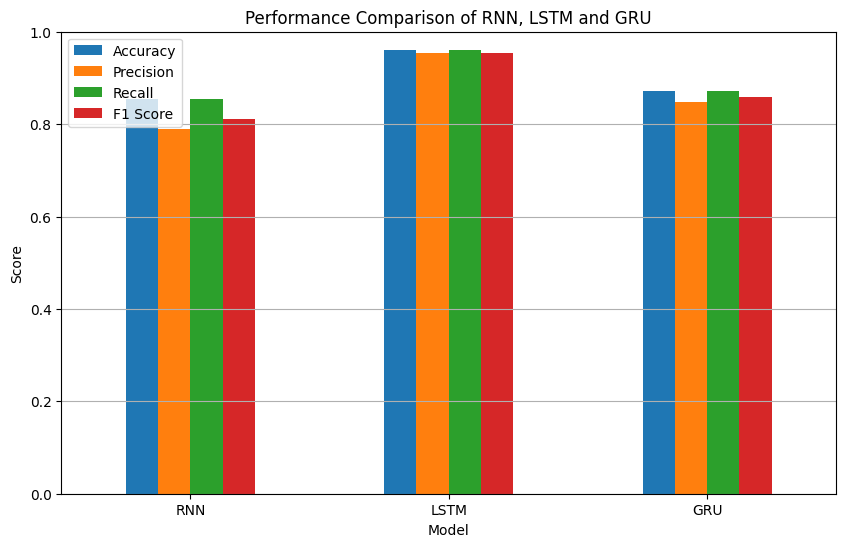

In [26]:

results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of RNN, LSTM and GRU")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

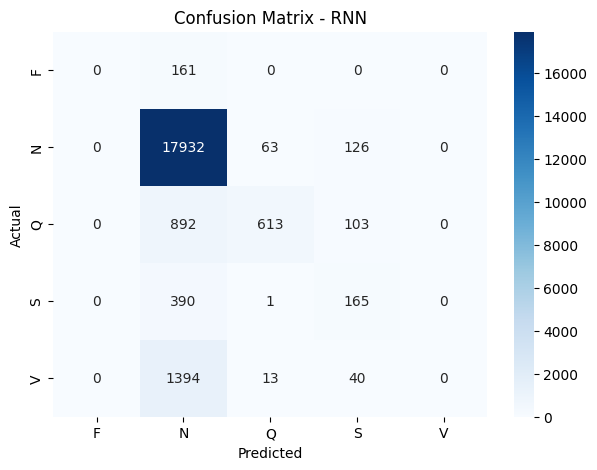

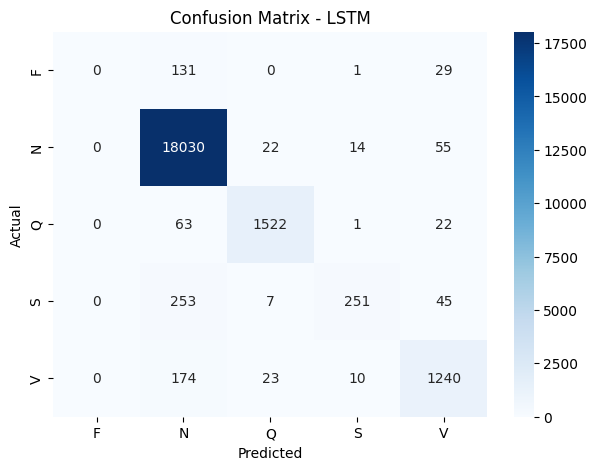

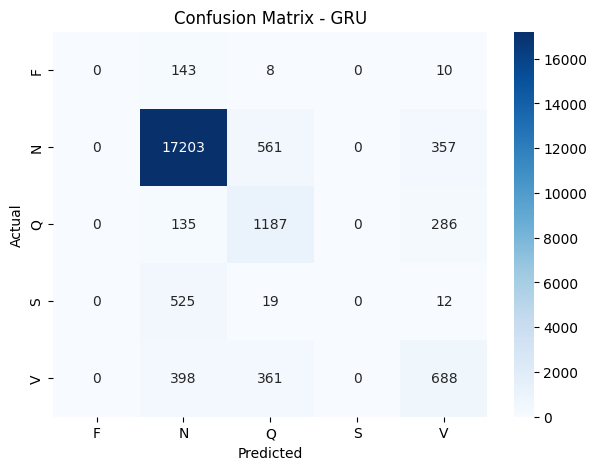

In [27]:

for name, model in models.items():

    predictions = model.predict(
        X_test,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    cm = confusion_matrix(
        y_test,
        predicted_classes
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

In [28]:

for name, model in models.items():

    predictions = model.predict(
        X_test,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    print("=" * 50)
    print(name)
    print("=" * 50)

    print(
        classification_report(
            y_test,
            predicted_classes,
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )

RNN
              precision    recall  f1-score   support

           F       0.00      0.00      0.00       161
           N       0.86      0.99      0.92     18121
           Q       0.89      0.38      0.53      1608
           S       0.38      0.30      0.33       556
           V       0.00      0.00      0.00      1447

    accuracy                           0.85     21893
   macro avg       0.43      0.33      0.36     21893
weighted avg       0.79      0.85      0.81     21893

LSTM
              precision    recall  f1-score   support

           F       0.00      0.00      0.00       161
           N       0.97      0.99      0.98     18121
           Q       0.97      0.95      0.96      1608
           S       0.91      0.45      0.60       556
           V       0.89      0.86      0.87      1447

    accuracy                           0.96     21893
   macro avg       0.75      0.65      0.68     21893
weighted avg       0.95      0.96      0.96     21893

GRU
         